<a href="https://colab.research.google.com/github/meiliesia/Seattle-Weather_EDA/blob/main/Seattle_Weather_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy

In [102]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [103]:
# Consistent colours for each weather type (used across all plots)
WEATHER_ORDER = ['sun', 'fog', 'drizzle', 'rain', 'snow']
WEATHER_COLORS = {'sun': '#F5B700', 'fog': '#8D99AE', 'drizzle': '#6FA8DC',
                  'rain': '#1D4E89', 'snow': '#9ADBE8'}
MONTH_LABELS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

In [104]:
df = pd.read_csv('https://raw.githubusercontent.com/meiliesia/Seattle-Weather-EDA/main/seattle-weather.csv', sep=';')
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,01/01/2012,0.0,12.8,5.0,4.7,drizzle
1,02/01/2012,10.9,10.6,2.8,4.5,rain
2,03/01/2012,0.8,11.7,7.2,2.3,rain
3,04/01/2012,20.3,12.2,5.6,4.7,rain
4,05/01/2012,1.3,8.9,2.8,6.1,rain


In [105]:
# Dataset structure: column names, dtypes, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   object 
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   object 
dtypes: float64(4), object(2)
memory usage: 68.6+ KB


In [106]:
print('Shape (rows, columns):', df.shape)
print('Columns:', list(df.columns))

Shape (rows, columns): (1461, 6)
Columns: ['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather']


In [107]:
#Check for missing value
df.isnull().sum()

,0
date,0
precipitation,0
temp_max,0
temp_min,0
wind,0
weather,0


In [108]:
#Check for duplicates
df.duplicated().sum()

np.int64(0)

In [109]:
#Summary statistics of numeric columns
df.describe()

,precipitation,temp_max,temp_min,wind
count,1461.000000,1461.000000,1461.000000,1461.000000
mean,3.029432,16.439083,8.234771,3.241136
std,6.680194,7.349758,5.023004,1.437825
min,0.000000,-1.600000,-7.100000,0.400000
25%,0.000000,10.600000,4.400000,2.200000
50%,0.000000,15.600000,8.300000,3.000000
75%,2.800000,22.200000,12.200000,4.000000
max,55.900000,35.600000,18.300000,9.500000


In [110]:
#Convert date to datetime (source format is dd/mm/yyyy)
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

In [111]:
print(df['date'].min())
print(df['date'].max())

2012-01-01 00:00:00
2015-12-31 00:00:00


In [112]:
df['month'] = df['date'].dt.month

In [113]:
#Logical consistency checks
print('Rows where temp_min > temp_max :', (df['temp_min'] > df['temp_max']).sum())
print('Negative precipitation values  :', (df['precipitation'] < 0).sum())
print('Weather categories             :', sorted(df['weather'].unique()))

Rows where temp_min > temp_max : 0
Negative precipitation values  : 0
Weather categories             : ['drizzle', 'fog', 'rain', 'snow', 'sun']


In [114]:
#Create calendar, season and rain features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day_of_year'] = df['date'].dt.dayofyear

season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
SEASON_ORDER = ['Winter', 'Spring', 'Summer', 'Autumn']
df['season'] = df['month'].map(season_map)

df['temp_mean'] = (df['temp_max'] + df['temp_min']) / 2   # approximate daily mean
df['temp_range'] = df['temp_max'] - df['temp_min']        # diurnal temperature range
df['is_wet_day'] = df['precipitation'] > 0                # any measurable precipitation
df['is_heavy_rain'] = df['precipitation'] >= 10           # heavy precipitation day (>= 10 mm)

df[['date','year','month','season','temp_mean','temp_range','is_wet_day','is_heavy_rain']].head()

,date,year,month,season,temp_mean,temp_range,is_wet_day,is_heavy_rain
0,2012-01-01,2012,1,Winter,8.90,7.8,False,False
1,2012-01-02,2012,1,Winter,6.70,7.8,True,True
2,2012-01-03,2012,1,Winter,9.45,4.5,True,False
3,2012-01-04,2012,1,Winter,8.90,6.6,True,True
4,2012-01-05,2012,1,Winter,5.85,6.1,True,False


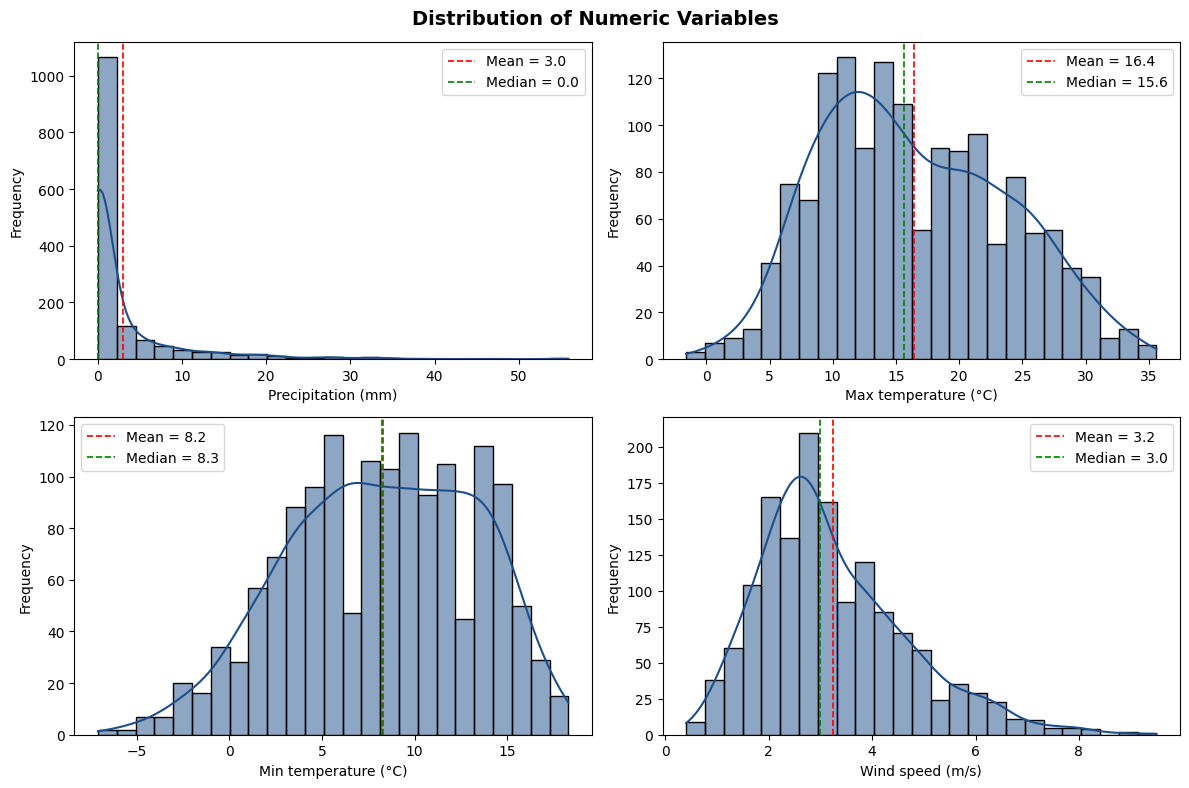

In [115]:
#Distribution of each numeric variable
num_cols = ['precipitation', 'temp_max', 'temp_min', 'wind']
labels = {'precipitation': 'Precipitation (mm)', 'temp_max': 'Max temperature (°C)',
          'temp_min': 'Min temperature (°C)', 'wind': 'Wind speed (m/s)'}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=25, kde=True, ax=ax, color='#1D4E89')
    ax.axvline(df[col].mean(), color='red', ls='--', lw=1.2, label=f'Mean = {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='green', ls='--', lw=1.2, label=f'Median = {df[col].median():.1f}')
    ax.set_xlabel(labels[col]); ax.set_ylabel('Frequency'); ax.legend()
plt.suptitle('Distribution of Numeric Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [116]:
#Shape of each distribution: skewness & kurtosis
shape_stats = pd.DataFrame({
    'skewness': df[num_cols].skew(),
    'kurtosis': df[num_cols].kurt()
}).round(2)
shape_stats

,skewness,kurtosis
precipitation,3.51,15.52
temp_max,0.28,-0.69
temp_min,-0.25,-0.60
wind,0.89,0.80


In [117]:
#Outlier detection (IQR)
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({'variable': col, 'lower_fence': round(low, 2), 'upper_fence': round(high, 2),
                 'n_outliers': n_out, 'pct_outliers': round(n_out / len(df) * 100, 1)})
pd.DataFrame(rows).set_index('variable')

,lower_fence,upper_fence,n_outliers,pct_outliers
variable,,,,
precipitation,-4.2,7.0,206,14.1
temp_max,-6.8,39.6,0,0.0
temp_min,-7.3,23.9,0,0.0
wind,-0.5,6.7,34,2.3


Dry days (0 mm)          : 57.4%
Wet days (> 0 mm)        : 42.6%
Heavy rain days (>=10 mm): 9.9%
Mean precipitation on wet days only: 7.10 mm


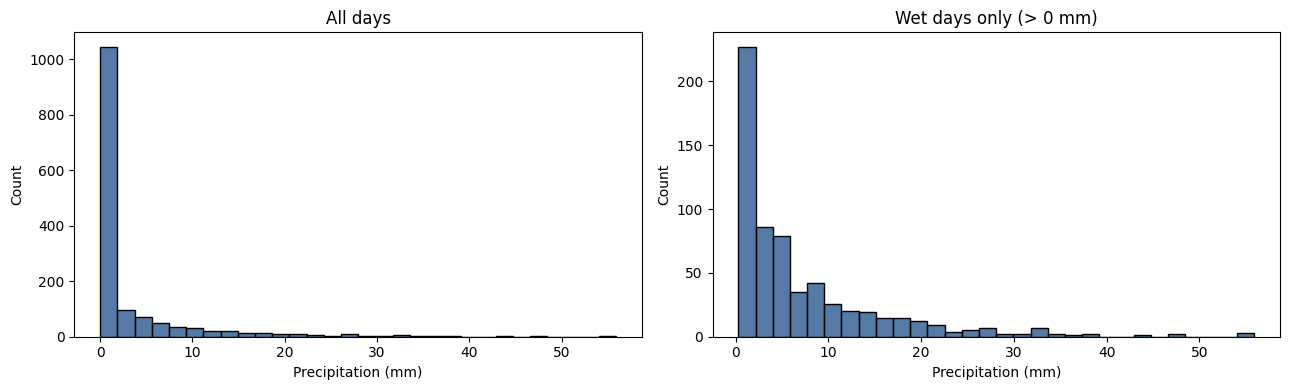

In [118]:
#Precipitation is zero-inflated
wet_share = df['is_wet_day'].mean() * 100
print(f'Dry days (0 mm)          : {100 - wet_share:.1f}%')
print(f'Wet days (> 0 mm)        : {wet_share:.1f}%')
print(f'Heavy rain days (>=10 mm): {df["is_heavy_rain"].mean() * 100:.1f}%')
print(f'Mean precipitation on wet days only: {df.loc[df["is_wet_day"], "precipitation"].mean():.2f} mm')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['precipitation'], bins=30, ax=axes[0], color='#1D4E89')
axes[0].set_title('All days'); axes[0].set_xlabel('Precipitation (mm)')
sns.histplot(df.loc[df['is_wet_day'], 'precipitation'], bins=30, ax=axes[1], color='#1D4E89')
axes[1].set_title('Wet days only (> 0 mm)'); axes[1].set_xlabel('Precipitation (mm)')
plt.tight_layout()
plt.show()

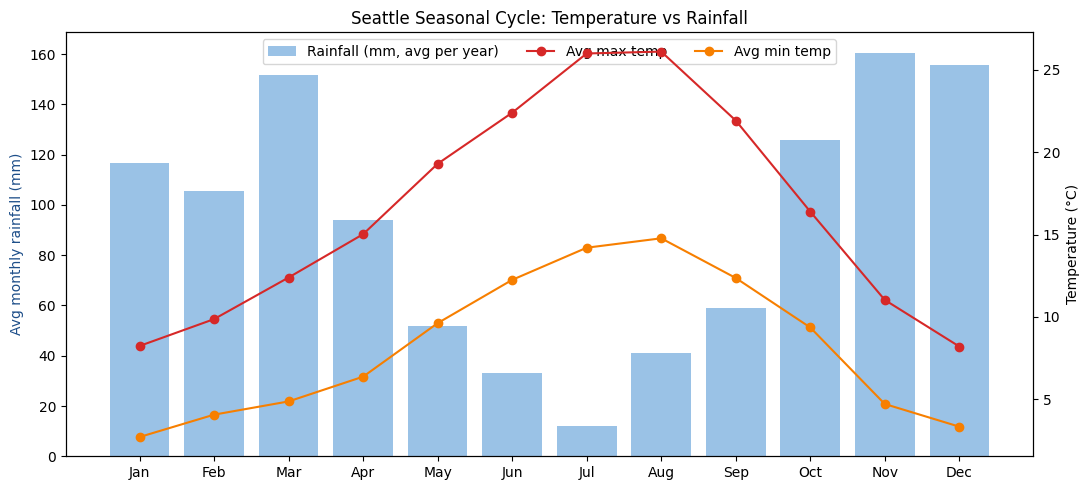

In [119]:
#Seasonal cycle: Temperature vs Rainfall
clim = df.groupby('month').agg(temp_max=('temp_max', 'mean'),
                               temp_min=('temp_min', 'mean'),
                               rain_total=('precipitation', 'sum'))
clim['rain_avg_per_year'] = clim['rain_total'] / df['year'].nunique()   # avg monthly total per year

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(clim.index, clim['rain_avg_per_year'], color='#6FA8DC', alpha=0.7, label='Rainfall (mm, avg per year)')
ax1.set_ylabel('Avg monthly rainfall (mm)', color='#1D4E89')
ax1.set_xticks(range(1, 13)); ax1.set_xticklabels(MONTH_LABELS)

ax2 = ax1.twinx()
ax2.plot(clim.index, clim['temp_max'], 'o-', color='#D62828', label='Avg max temp')
ax2.plot(clim.index, clim['temp_min'], 'o-', color='#F77F00', label='Avg min temp')
ax2.set_ylabel('Temperature (°C)')
ax2.grid(False)

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper center', ncol=3, frameon=True)
plt.title('Seattle Seasonal Cycle: Temperature vs Rainfall')
plt.tight_layout()
plt.show()

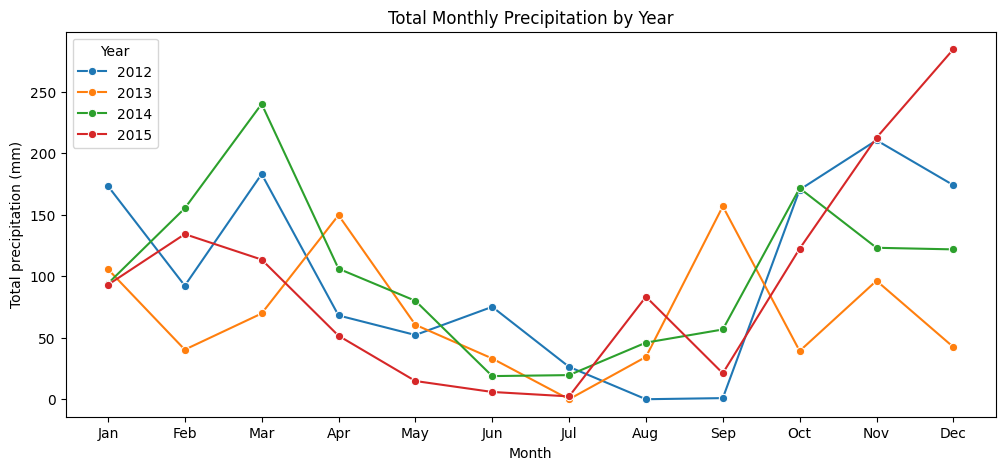

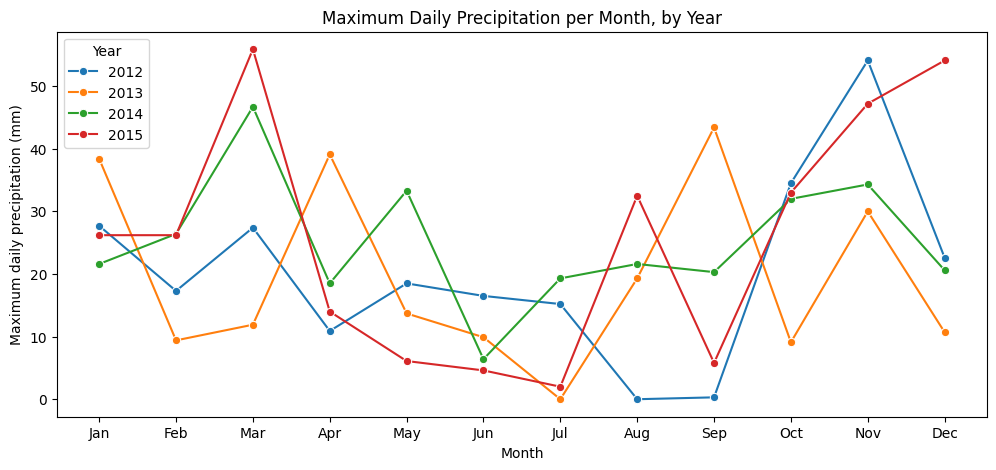

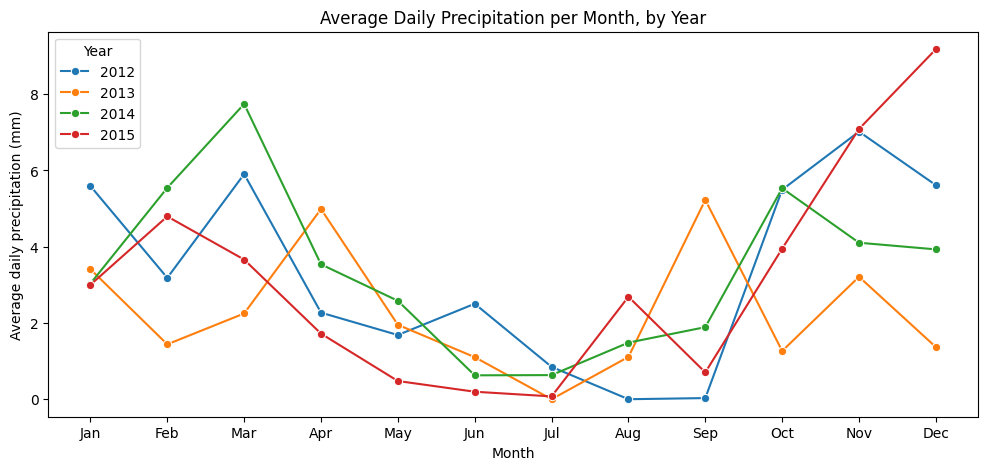

In [120]:
#Monthly precipitation (total, maximum, average) by year
def monthly_lineplot(agg, ylabel, title):
    data = df.groupby(['year', 'month'])['precipitation'].agg(agg).reset_index()
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=data, x='month', y='precipitation', hue='year', marker='o', palette='tab10')
    plt.xticks(range(1, 13), MONTH_LABELS)
    plt.xlabel('Month'); plt.ylabel(ylabel); plt.title(title)
    plt.legend(title='Year')
    plt.show()

monthly_lineplot('sum', 'Total precipitation (mm)', 'Total Monthly Precipitation by Year')
monthly_lineplot('max', 'Maximum daily precipitation (mm)', 'Maximum Daily Precipitation per Month, by Year')
monthly_lineplot('mean', 'Average daily precipitation (mm)', 'Average Daily Precipitation per Month, by Year')

In [121]:
#Annual totals and number of wet days per year
yearly = df.groupby('year').agg(total_precip_mm=('precipitation', 'sum'),
                                wet_days=('is_wet_day', 'sum'),
                                heavy_rain_days=('is_heavy_rain', 'sum'),
                                avg_temp_max=('temp_max', 'mean'),
                                avg_temp_min=('temp_min', 'mean'),
                                avg_wind=('wind', 'mean')).round(2)
yearly

,total_precip_mm,wet_days,heavy_rain_days,avg_temp_max,avg_temp_min,avg_wind
year,,,,,,
2012,1226.0,177,42,15.28,7.29,3.40
2013,828.0,152,21,16.06,8.15,3.02
2014,1232.8,150,47,17.00,8.66,3.39
2015,1139.2,144,34,17.43,8.84,3.16


In [122]:
#Longest dry spell (consecutive days with 0 mm) in each year
def longest_dry_spell(group):
    dry = (group['precipitation'] == 0)
    run_id = (dry != dry.shift()).cumsum()
    runs = dry.groupby(run_id).agg(['first', 'size'])
    return runs.loc[runs['first'], 'size'].max()

dry_spells = df.groupby('year').apply(longest_dry_spell).rename('longest_dry_spell_days')
dry_spells

/tmp/ipykernel_2765/3825494285.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dry_spells = df.groupby('year').apply(longest_dry_spell).rename('longest_dry_spell_days')


,longest_dry_spell_days
year,
2012,48
2013,35
2014,23
2015,25


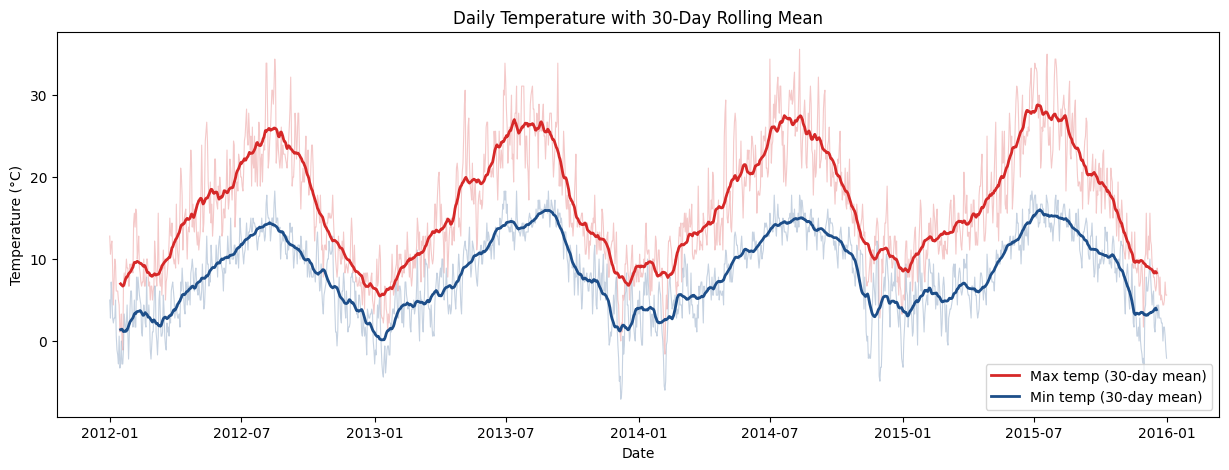

In [123]:
#Daily temperatures with a 30-day rolling mean to reveal the trend underneath the daily noise
ts = df.set_index('date')[['temp_max', 'temp_min']]
roll = ts.rolling(30, center=True).mean()

plt.figure(figsize=(15, 5))
plt.plot(ts.index, ts['temp_max'], color='#D62828', alpha=0.25, lw=0.8)
plt.plot(ts.index, ts['temp_min'], color='#1D4E89', alpha=0.25, lw=0.8)
plt.plot(roll.index, roll['temp_max'], color='#D62828', lw=2, label='Max temp (30-day mean)')
plt.plot(roll.index, roll['temp_min'], color='#1D4E89', lw=2, label='Min temp (30-day mean)')
plt.title('Daily Temperature with 30-Day Rolling Mean')
plt.xlabel('Date'); plt.ylabel('Temperature (°C)'); plt.legend()
plt.show()

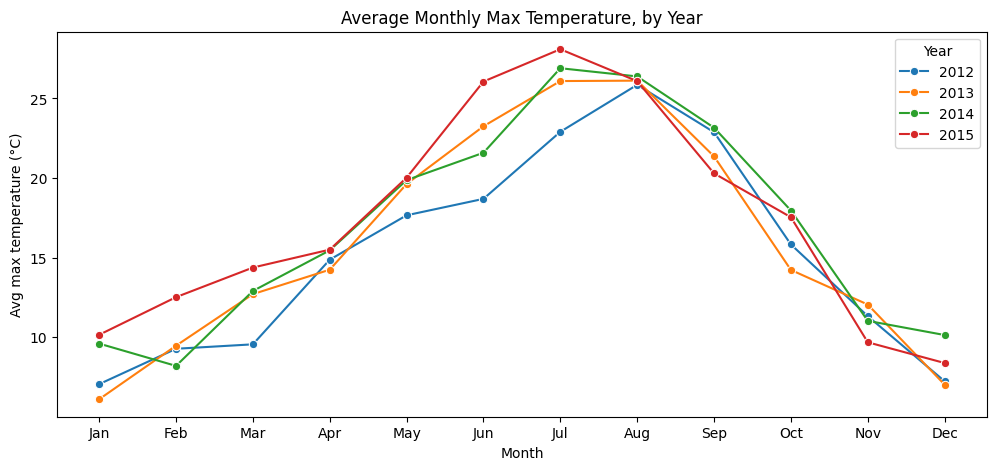

In [124]:
#Average max temperature per month, one line per year
avg_tmax = df.groupby(['year', 'month'])['temp_max'].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=avg_tmax, x='month', y='temp_max', hue='year', marker='o', palette='tab10')
plt.xticks(range(1, 13), MONTH_LABELS)
plt.xlabel('Month'); plt.ylabel('Avg max temperature (°C)')
plt.title('Average Monthly Max Temperature, by Year')
plt.legend(title='Year')
plt.show()

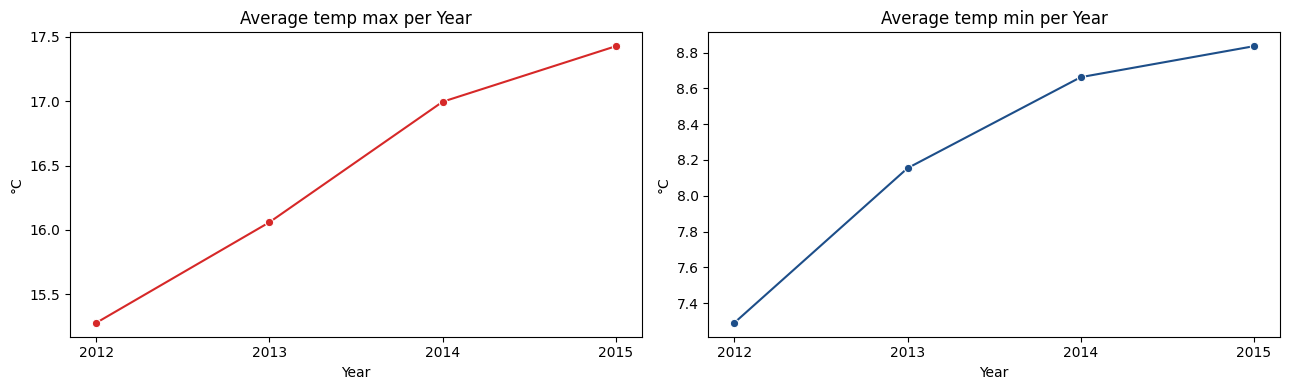

In [125]:
#Yearly averages of max and min temperature
yearly_temp = df.groupby('year')[['temp_max', 'temp_min']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, color in zip(axes, ['temp_max', 'temp_min'], ['#D62828', '#1D4E89']):
    sns.lineplot(data=yearly_temp, x='year', y=col, marker='o', ax=ax, color=color)
    ax.set_xticks(yearly_temp['year'])
    ax.set_title(f'Average {col.replace("_", " ")} per Year')
    ax.set_xlabel('Year'); ax.set_ylabel('°C')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2765/3657087500.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(MONTH_LABELS); axes[2].set_title('Wind Speed by Month')


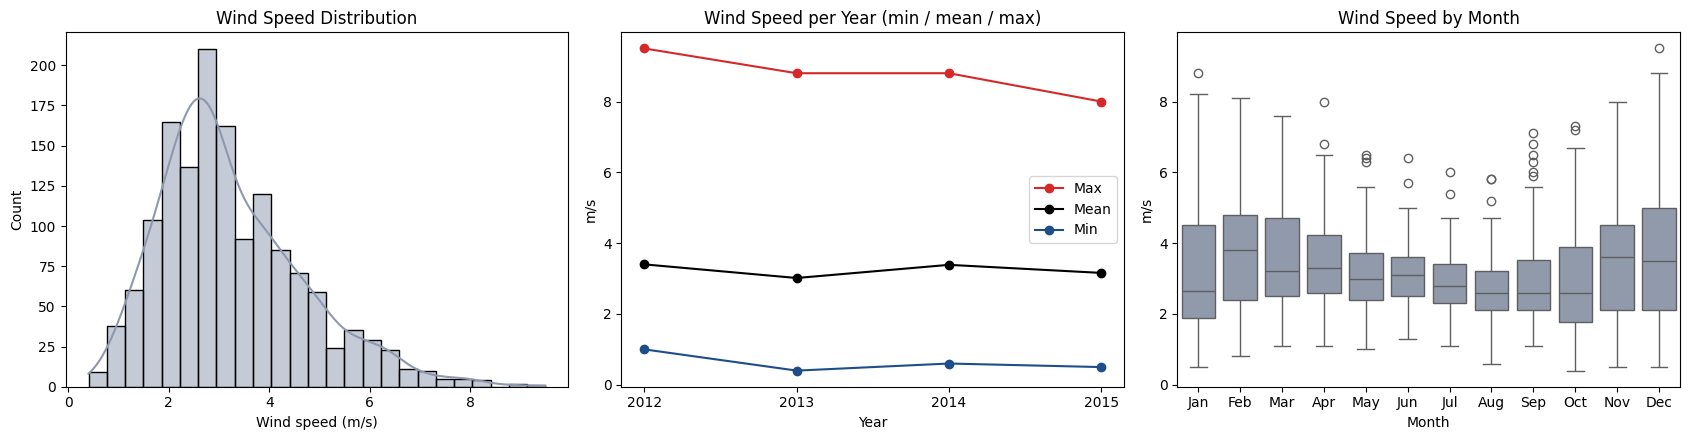

In [126]:
#Wind: distribution, yearly range and monthly pattern
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df['wind'], bins=25, kde=True, ax=axes[0], color='#8D99AE')
axes[0].set_title('Wind Speed Distribution'); axes[0].set_xlabel('Wind speed (m/s)')

wind_year = df.groupby('year')['wind'].agg(['min', 'mean', 'max']).reset_index()
for col, c in zip(['max', 'mean', 'min'], ['#D62828', 'black', '#1D4E89']):
    axes[1].plot(wind_year['year'], wind_year[col], 'o-', color=c, label=col.capitalize())
axes[1].set_xticks(wind_year['year']); axes[1].legend()
axes[1].set_title('Wind Speed per Year (min / mean / max)'); axes[1].set_xlabel('Year'); axes[1].set_ylabel('m/s')

sns.boxplot(data=df, x='month', y='wind', ax=axes[2], color='#8D99AE')
axes[2].set_xticklabels(MONTH_LABELS); axes[2].set_title('Wind Speed by Month')
axes[2].set_xlabel('Month'); axes[2].set_ylabel('m/s')
plt.tight_layout()
plt.show()

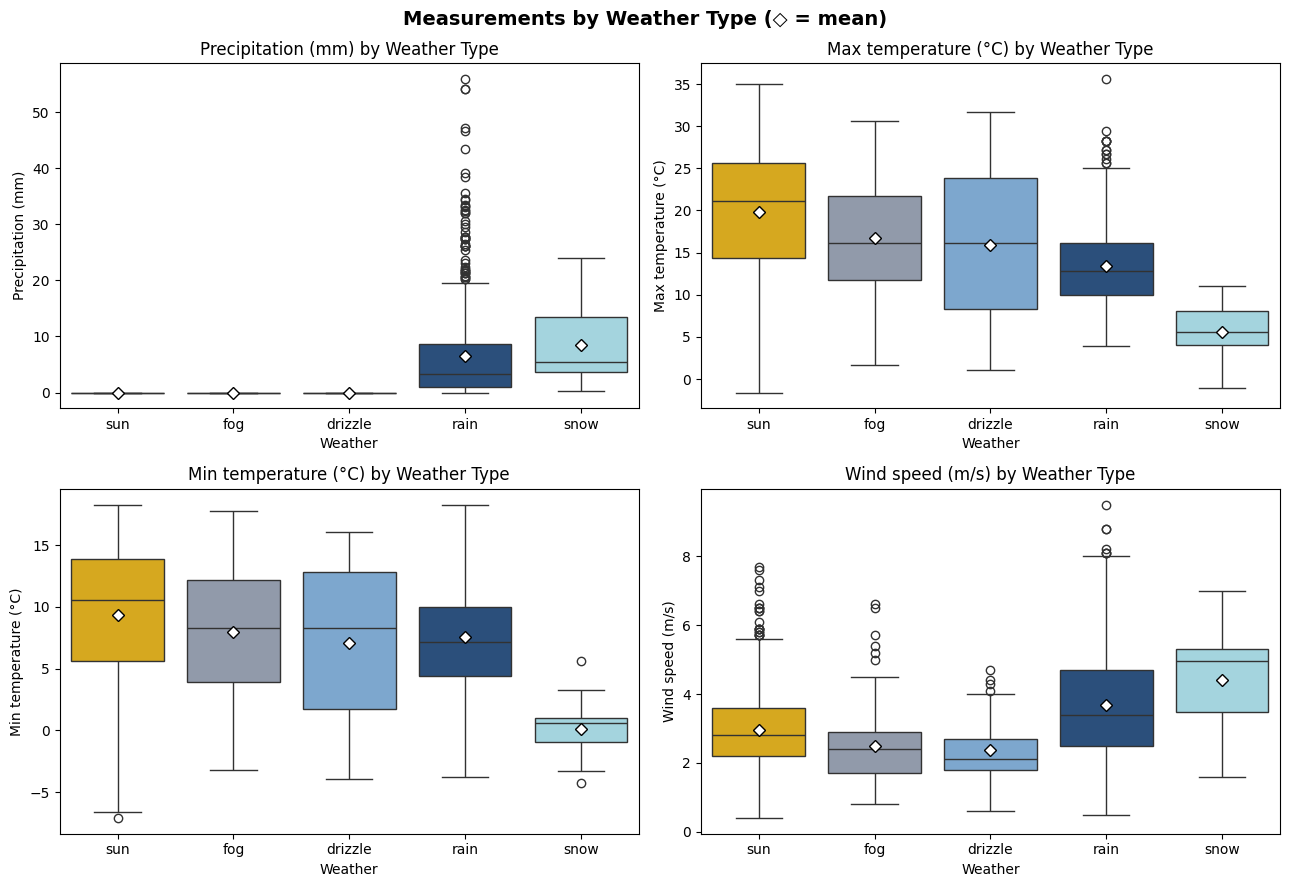

In [127]:
#Distribution of each variable per weather type
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x='weather', y=col, order=WEATHER_ORDER, hue='weather',
                palette=WEATHER_COLORS, legend=False, showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}, ax=ax)
    ax.set_xlabel('Weather'); ax.set_ylabel(labels[col]); ax.set_title(labels[col] + ' by Weather Type')
plt.suptitle('Measurements by Weather Type (◇ = mean)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [128]:
#Mean values per weather type
df.groupby('weather')[num_cols].mean().loc[WEATHER_ORDER].round(2)

,precipitation,temp_max,temp_min,wind
weather,,,,
sun,0.00,19.86,9.34,2.96
fog,0.00,16.76,7.98,2.48
drizzle,0.00,15.93,7.11,2.37
rain,6.56,13.45,7.59,3.67
snow,8.55,5.57,0.15,4.41


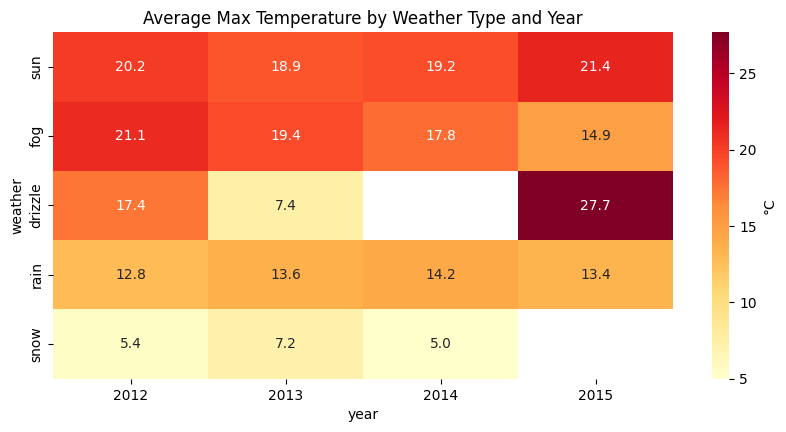

In [129]:
#Average max temperature by weather type and year
pivot_temp = df.pivot_table(values='temp_max', index='weather', columns='year', aggfunc='mean').loc[WEATHER_ORDER]

plt.figure(figsize=(10, 4.5))
sns.heatmap(pivot_temp, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': '°C'})
plt.title('Average Max Temperature by Weather Type and Year')
plt.show()

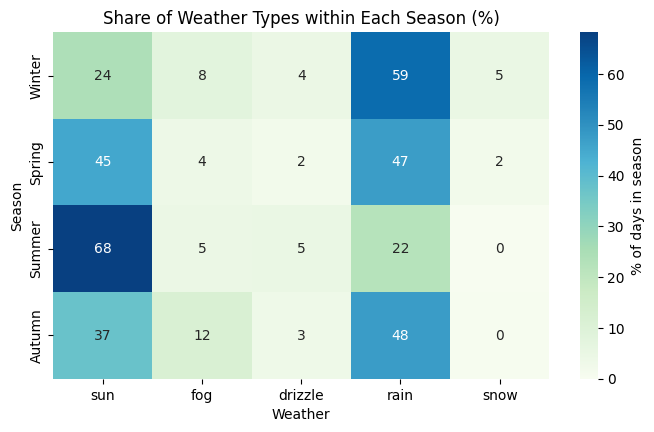

In [130]:
#Weather types within each season
season_weather = pd.crosstab(df['season'], df['weather'], normalize='index').loc[SEASON_ORDER, WEATHER_ORDER] * 100

plt.figure(figsize=(8, 4.5))
sns.heatmap(season_weather, annot=True, fmt='.0f', cmap='GnBu', cbar_kws={'label': '% of days in season'})
plt.title('Share of Weather Types within Each Season (%)')
plt.xlabel('Weather'); plt.ylabel('Season')
plt.show()

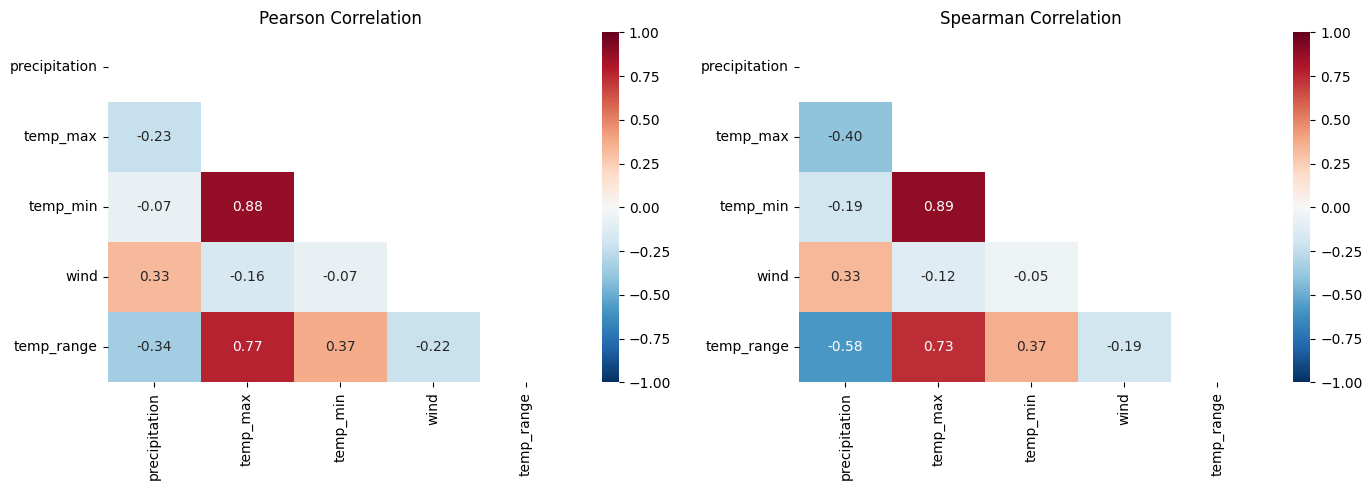

In [131]:
#Correlation matrix (Pearson and Spearman)
corr_cols = ['precipitation', 'temp_max', 'temp_min', 'wind', 'temp_range']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = df[corr_cols].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, ax=ax)
    ax.set_title(f'{method.capitalize()} Correlation')
plt.tight_layout()
plt.show()

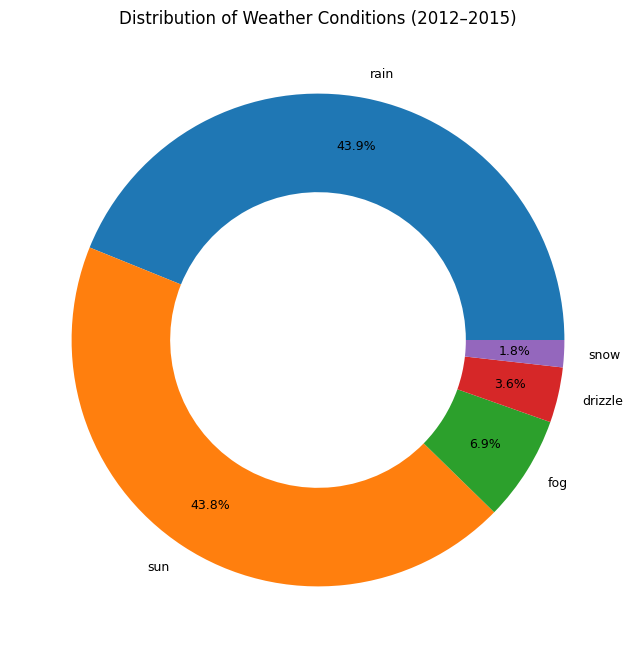

In [142]:
#Weather type frequency
counts = df['weather'].value_counts()

plt.figure(figsize=(8,8))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%',
        startangle=0, pctdistance=0.8, textprops={'fontsize': 9},
        wedgeprops={'width': 0.4})
plt.title('Distribution of Weather Conditions (2012–2015)')
plt.show()

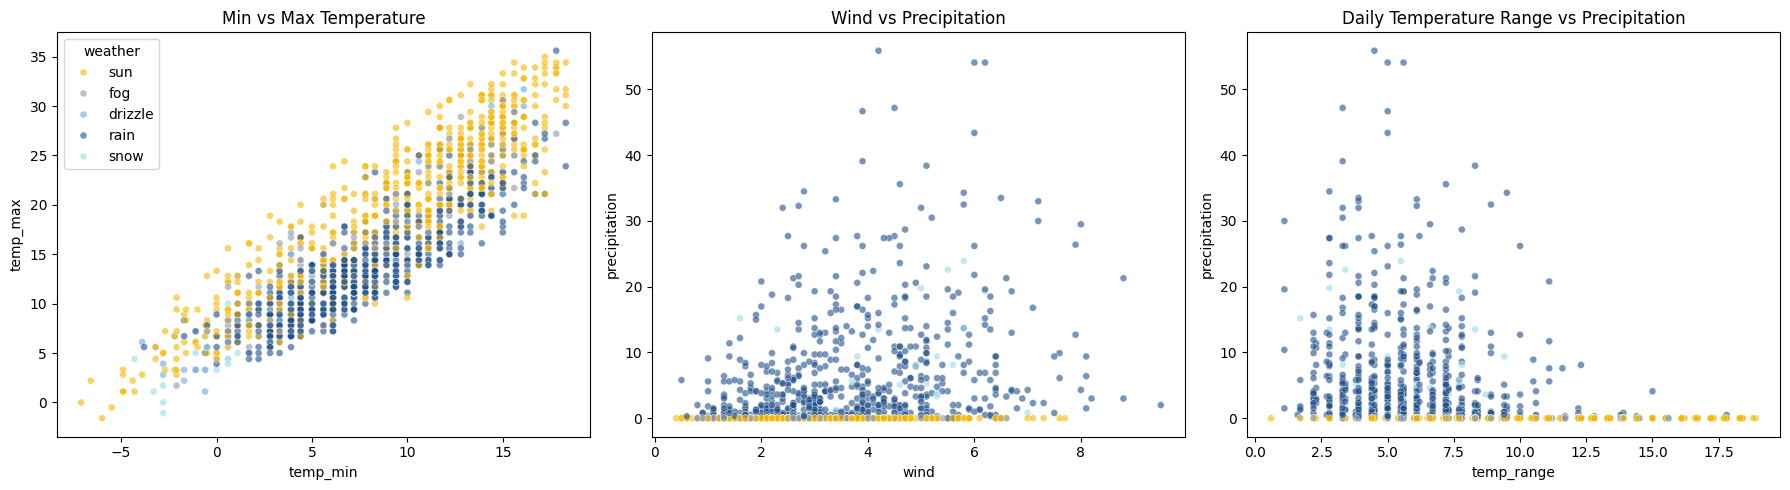

In [133]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='temp_min', y='temp_max', hue='weather', hue_order=WEATHER_ORDER,
                palette=WEATHER_COLORS, alpha=0.6, s=25, ax=axes[0])
axes[0].set_title('Min vs Max Temperature')

sns.scatterplot(data=df, x='wind', y='precipitation', hue='weather', hue_order=WEATHER_ORDER,
                palette=WEATHER_COLORS, alpha=0.6, s=25, ax=axes[1], legend=False)
axes[1].set_title('Wind vs Precipitation')

sns.scatterplot(data=df, x='temp_range', y='precipitation', hue='weather', hue_order=WEATHER_ORDER,
                palette=WEATHER_COLORS, alpha=0.6, s=25, ax=axes[2], legend=False)
axes[2].set_title('Daily Temperature Range vs Precipitation')
plt.tight_layout()
plt.show()